# Tour-Level PCA — DT-CARGO Vehicle Telemetry Analysis

**Purpose:** Build a new, reproducible PCA representation for retained candidate tours, following the existing track-level PCA work without modifying it.

**Analysis unit:** one retained `(vehicle_id, tour_id)` candidate tour.

**Input:** `data/processed/tour_level/retained_tours_quality_checked.csv`

**Principles**
- Preserve the source dataset and quality flags.
- Do not treat a quality flag as an automatic reason to delete a tour.
- Exclude identifiers, timestamps, endpoint flags, review flags, and categorical metadata from PCA inputs.
- Fit imputation, scaling, and PCA on the tour-level data only.
- Keep the standardized original features alongside the PCA representation for later clustering comparisons.
- Record limitations: candidate tours are not independently verified trips; the endpoint filter excluded groups representing 17.22% of recorded distance in the current project audit.


## 1. Imports and reproducibility

This notebook uses the existing project dependencies (`pandas`, `numpy`, `matplotlib`, and `scikit-learn`). Run cells from top to bottom in VS Code.


In [1]:
from pathlib import Path
import json
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA

RANDOM_STATE = 42
VARIANCE_THRESHOLD = 0.90

print("pandas:", pd.__version__)
print("numpy:", np.__version__)


pandas: 3.0.3
numpy: 2.4.6


## 2. Locate the project and load the quality-checked tour dataset

The path resolver checks the current directory and its parents. If the repository is not opened as the current workspace, set `PROJECT_ROOT` manually to the local repository root.


In [2]:
# Find the repository root from the current working directory.
cwd = Path.cwd().resolve()
candidates = [cwd, *cwd.parents]

PROJECT_ROOT = next(
    (p for p in candidates
     if (p / "data" / "processed" / "tour_level" /
         "retained_tours_quality_checked.csv").exists()),
    None
)

if PROJECT_ROOT is None:
    # If running from a notebooks/ directory before the output exists,
    # try locating a repository root by its notebooks/ and data/ folders.
    PROJECT_ROOT = next(
        (p for p in candidates
         if (p / "notebooks").is_dir() and (p / "data").is_dir()),
        None
    )

if PROJECT_ROOT is None:
    raise FileNotFoundError(
        "Could not locate the repository root. Set PROJECT_ROOT manually "
        "to the local dt-cargo-vehicle-telemetry- repository folder."
    )

DATA_PATH = (
    PROJECT_ROOT / "data" / "processed" / "tour_level" /
    "retained_tours_quality_checked.csv"
)
OUTPUT_DIR = PROJECT_ROOT / "data" / "processed" / "tour_level_pca"
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

print("Working directory:", cwd)
print("Project root:", PROJECT_ROOT)
print("Input exists:", DATA_PATH.exists())
print("Input path:", DATA_PATH)

if not DATA_PATH.exists():
    raise FileNotFoundError(
        f"Expected tour dataset not found at {DATA_PATH}. "
        "Check that Bhargesh's tour-level processing notebook has been run "
        "and that the CSV is present locally."
    )

tours = pd.read_csv(DATA_PATH)
print("Loaded shape:", tours.shape)
display(tours.head())


Working directory: /Users/divyshah/Downloads/dt-cargo-vehicle-telemetry--main/notebooks
Project root: /Users/divyshah/Downloads/dt-cargo-vehicle-telemetry--main
Input exists: True
Input path: /Users/divyshah/Downloads/dt-cargo-vehicle-telemetry--main/data/processed/tour_level/retained_tours_quality_checked.csv
Loaded shape: (13413, 26)


,vehicle_id,tour_id,track_count,start_time,last_track_start,end_time,total_distance_km,total_valid_track_duration_seconds,valid_duration_track_count,home_base_endpoint,...,service_area_fuel,industrial_area,home_base,cid,negative_elapsed_span,non_positive_distance,duration_incomplete,duration_unusable,high_distance_based_speed,requires_quality_review
0,1,0,3,2021-09-10 09:04:53.598000+00:00,2021-09-10 11:25:20.146000+00:00,2021-09-10 12:09:50.802000+00:00,57.945,7412.956,3,True,...,False,True,False,149,False,False,False,False,False,False
1,1,1,7,2021-09-10 12:21:35.547000+00:00,2021-09-13 06:08:10.018000+00:00,2021-09-13 06:08:26.837000+00:00,0.371,763.286,7,True,...,False,True,True,0,False,False,False,False,False,False
2,1,2,8,2021-09-13 06:25:03.766000+00:00,2021-09-14 11:24:50.310000+00:00,2021-09-14 11:45:39.906000+00:00,36.554,4767.617,8,True,...,False,True,False,301,False,False,False,False,False,False
3,1,3,104,2021-09-14 11:49:23.603000+00:00,2021-10-07 08:44:23.587000+00:00,2021-10-07 08:49:40.058000+00:00,6.757,17947.817,104,True,...,False,True,True,0,False,False,False,False,False,False
4,1,4,16,2021-10-07 10:19:52.098000+00:00,2021-10-09 06:35:21.071000+00:00,2021-10-09 07:59:24.414000+00:00,1291.041,74143.179,16,True,...,False,True,False,149,False,False,False,False,False,False


## 3. Verify schema, keys, and quality flags

This is a targeted input validation step, not a repetition of the completed track-level EDA. We check that the file is the expected tour-level artifact and inspect the flags relevant to feature selection.


In [4]:
print("Shape:", tours.shape)
print("\nColumns:")
print(tours.columns.tolist())

key_cols = ["vehicle_id", "tour_id"]
missing_keys = [c for c in key_cols if c not in tours.columns]
if missing_keys:
    raise ValueError(f"Required tour keys missing: {missing_keys}")

print("\nMissing key values:")
display(tours[key_cols].isna().sum().to_frame("missing_count"))

print("Duplicate (vehicle_id, tour_id) rows:",
      tours.duplicated(subset=key_cols).sum())

quality_cols = [
    c for c in tours.columns
    if c in {
        "negative_elapsed_span", "non_positive_distance",
        "duration_incomplete", "duration_unusable",
        "high_distance_based_speed", "requires_quality_review"
    }
]
if quality_cols:
    display(tours[quality_cols].sum(numeric_only=True).to_frame("flagged_tours"))

if len(tours) != tours.dropna(subset=key_cols).shape[0]:
    warnings.warn("Some rows have missing tour keys; inspect before modeling.")

if tours.duplicated(subset=key_cols).any():
    raise ValueError("Expected one row per (vehicle_id, tour_id); duplicate groups found.")


Shape: (13413, 26)

Columns:
['vehicle_id', 'tour_id', 'track_count', 'start_time', 'last_track_start', 'end_time', 'total_distance_km', 'total_valid_track_duration_seconds', 'valid_duration_track_count', 'home_base_endpoint', 'elapsed_span_hours', 'recorded_track_hours', 'distance_based_avg_speed_kmh', 'fleet_test_id', 'long_haul', 'rest_area', 'service_area_fuel', 'industrial_area', 'home_base', 'cid', 'negative_elapsed_span', 'non_positive_distance', 'duration_incomplete', 'duration_unusable', 'high_distance_based_speed', 'requires_quality_review']

Missing key values:


,missing_count
vehicle_id,0
tour_id,0


Duplicate (vehicle_id, tour_id) rows: 0


,flagged_tours
negative_elapsed_span,1
non_positive_distance,16
duration_incomplete,237
duration_unusable,5
high_distance_based_speed,16
requires_quality_review,264


## 4. Select candidate numeric features for PCA

PCA should represent operational characteristics, not identifiers or labels. Start with the core tour-level numeric measures that are available in the supplied project summary.

We deliberately exclude:
- `vehicle_id`, `tour_id`: identifiers
- timestamps: not direct numeric PCA inputs
- `home_base_endpoint`: endpoint selection flag
- quality/review flags: diagnostic labels, not continuous operational features
- metadata such as `fleet_test_id`, `cid`, and Boolean context flags: better retained for post-PCA interpretation rather than encoded as arbitrary numbers

`track_count` is retained as a candidate measure of tour segmentation/recording granularity. It may correlate with total duration or distance, so we will inspect correlations before deciding whether to keep it.


In [5]:
candidate_features = [
    "total_distance_km",
    "recorded_track_hours",
    "elapsed_span_hours",
    "distance_based_avg_speed_kmh",
    "track_count",
]

missing_features = [c for c in candidate_features if c not in tours.columns]
if missing_features:
    raise ValueError(
        "Expected candidate features are missing: "
        f"{missing_features}. Review the input schema and update this list "
        "only after confirming the actual column definitions."
    )

X_candidates = tours[candidate_features].apply(pd.to_numeric, errors="coerce")

feature_audit = pd.DataFrame({
    "dtype_after_numeric_conversion": X_candidates.dtypes.astype(str),
    "missing_count": X_candidates.isna().sum(),
    "missing_percent": (X_candidates.isna().mean() * 100).round(2),
    "minimum": X_candidates.min(),
    "median": X_candidates.median(),
    "maximum": X_candidates.max(),
    "skewness": X_candidates.skew(),
})
display(feature_audit.round(4))


,dtype_after_numeric_conversion,missing_count,missing_percent,minimum,median,maximum,skewness
total_distance_km,float64,0,0.00,0.0000,22.9630,7714.3690,7.0169
recorded_track_hours,float64,0,0.00,0.0000,1.5111,222.0112,9.8130
elapsed_span_hours,float64,5,0.04,0.0002,4.3845,4024.9366,15.6348
distance_based_avg_speed_kmh,float64,5,0.04,0.0000,17.0221,653.9036,3.2473
track_count,int64,0,0.00,1.0000,4.0000,2138.0000,28.8243


## 5. Inspect distributions and redundancy

Distance, duration, and elapsed span can be strongly right-skewed. `log1p` is appropriate only for non-negative values. Negative values are not silently transformed; they are reported and left missing for the affected derived feature in the modeling copy.


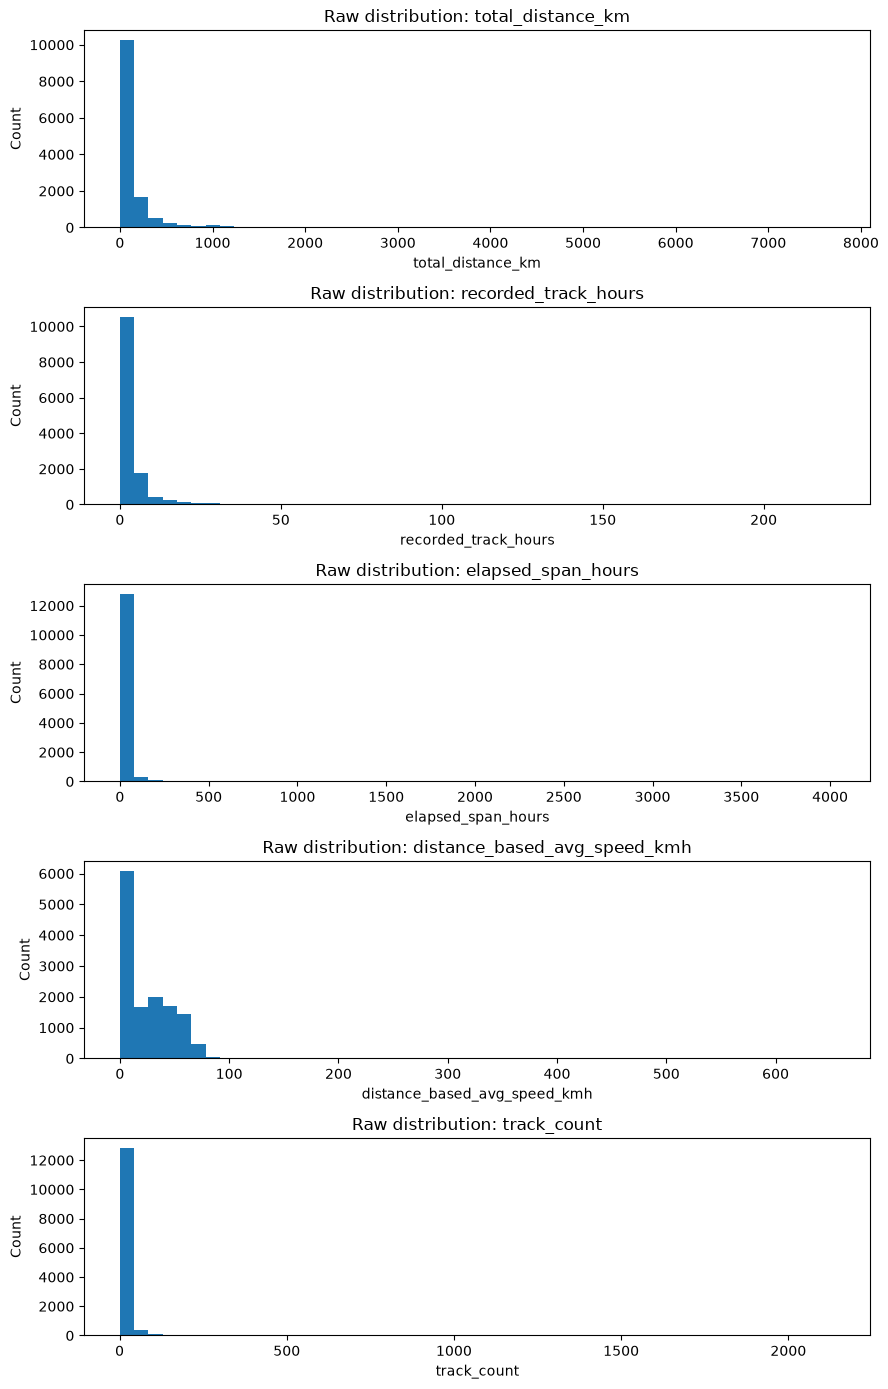

Pearson correlation on available values:


,total_distance_km,recorded_track_hours,elapsed_span_hours,distance_based_avg_speed_kmh,track_count
total_distance_km,1.000,0.770,0.350,0.486,0.239
recorded_track_hours,0.770,1.000,0.398,0.279,0.594
elapsed_span_hours,0.350,0.398,1.000,0.038,0.272
distance_based_avg_speed_kmh,0.486,0.279,0.038,1.000,-0.030
track_count,0.239,0.594,0.272,-0.030,1.000


In [6]:
fig, axes = plt.subplots(
    nrows=len(candidate_features), ncols=1,
    figsize=(9, 2.8 * len(candidate_features))
)
for ax, col in zip(axes, candidate_features):
    values = X_candidates[col].dropna()
    ax.hist(values, bins=50)
    ax.set_title(f"Raw distribution: {col}")
    ax.set_xlabel(col)
    ax.set_ylabel("Count")
plt.tight_layout()
plt.show()

print("Pearson correlation on available values:")
display(X_candidates.corr().round(3))


## 6. Create a modeling copy and apply justified transformations

Use `log1p` for non-negative distance, recorded duration, elapsed span, and track count. Average speed is kept on its original scale at this stage because it is a ratio derived from distance and recorded duration; inspect its distribution before considering another transform.

Rows with negative values in log-transformed features are treated as missing for that feature only, while original values remain unchanged in `tours`. No tour is dropped solely because a quality-review flag is set.


In [7]:
X_model = X_candidates.copy()

log_features = [
    "total_distance_km",
    "recorded_track_hours",
    "elapsed_span_hours",
    "track_count",
]

for col in log_features:
    negative_mask = X_model[col] < 0
    negative_count = int(negative_mask.sum())
    if negative_count:
        print(f"{col}: setting {negative_count} negative modeling values to NaN")
        X_model.loc[negative_mask, col] = np.nan
    X_model[col] = np.log1p(X_model[col])

# Negative or zero speeds are not automatically declared erroneous here.
# A non-positive speed can arise in groups with zero/missing distance or
# unusable duration, so preserve the numeric value and review its distribution.
print("Missing values after transformation:")
display(X_model.isna().sum().to_frame("missing_count"))
display(X_model.describe().T.round(4))


Missing values after transformation:


,missing_count
total_distance_km,0
recorded_track_hours,0
elapsed_span_hours,5
distance_based_avg_speed_kmh,5
track_count,0


,count,mean,std,min,25%,50%,75%,max
total_distance_km,13413.0,3.0160,2.2022,0.0000,0.7603,3.1765,4.9054,8.9510
recorded_track_hours,13413.0,1.0382,0.8549,0.0000,0.2955,0.9207,1.5949,5.4072
elapsed_span_hours,13408.0,1.8347,1.3384,0.0002,0.8023,1.6835,2.5562,8.3005
distance_based_avg_speed_kmh,13408.0,24.2362,23.7133,0.0000,3.7274,17.0221,41.1551,653.9036
track_count,13413.0,1.8007,0.8771,0.6931,1.0986,1.6094,2.1972,7.6681


## 7. Missingness and row eligibility

The PCA pipeline uses median imputation for the selected features. This is a practical baseline, not recovery of the true unknown values. A tour with all selected features missing cannot be meaningfully imputed and is excluded from this PCA fit; its key remains available for an audit.


In [8]:
all_missing_mask = X_model.isna().all(axis=1)
print("Tours with all selected PCA features missing:", int(all_missing_mask.sum()))

if all_missing_mask.any():
    all_missing_audit = tours.loc[all_missing_mask, key_cols].copy()
    all_missing_audit.to_csv(OUTPUT_DIR / "tour_level_pca_all_features_missing.csv", index=False)
    print("Saved all-feature-missing audit.")

eligible_mask = ~all_missing_mask
tour_keys_eligible = tours.loc[eligible_mask, key_cols].reset_index(drop=True)
X_eligible = X_model.loc[eligible_mask].reset_index(drop=True)

imputer = SimpleImputer(strategy="median")
X_imputed_array = imputer.fit_transform(X_eligible)
X_imputed = pd.DataFrame(
    X_imputed_array,
    columns=X_eligible.columns,
    index=X_eligible.index
)

print("Input tour rows:", len(tours))
print("Eligible PCA rows:", len(X_imputed))
print("Features:", X_imputed.shape[1])
print("Remaining missing values:", int(X_imputed.isna().sum().sum()))


Tours with all selected PCA features missing: 0
Input tour rows: 13413
Eligible PCA rows: 13413
Features: 5
Remaining missing values: 0


## 8. Standardize the tour-level features

PCA is scale-sensitive. Standardization is fitted on the current tour-level feature matrix, independently of all track-level experiments.


In [9]:
scaler = StandardScaler()
X_scaled_array = scaler.fit_transform(X_imputed)
X_scaled = pd.DataFrame(
    X_scaled_array,
    columns=X_imputed.columns,
    index=X_imputed.index
)

scaled_check = pd.DataFrame({
    "mean": X_scaled.mean(),
    "std_population": X_scaled.std(ddof=0),
})
display(scaled_check.round(6))


,mean,std_population
total_distance_km,0.0,1.0
recorded_track_hours,0.0,1.0
elapsed_span_hours,0.0,1.0
distance_based_avg_speed_kmh,-0.0,1.0
track_count,0.0,1.0


## 9. Fit PCA and inspect explained variance

Fit PCA with all available components first. Choose the retained component count from the cumulative variance threshold; do not assume the track-level result of six components will apply to tours.


In [10]:
pca_full = PCA()
scores_array = pca_full.fit_transform(X_scaled)

component_names = [f"PC{i+1}" for i in range(scores_array.shape[1])]
X_pca_full = pd.DataFrame(scores_array, columns=component_names)

explained_variance = pd.DataFrame({
    "component": component_names,
    "eigenvalue": pca_full.explained_variance_,
    "individual_variance_pct": pca_full.explained_variance_ratio_ * 100,
    "cumulative_variance_pct": np.cumsum(pca_full.explained_variance_ratio_) * 100,
})
display(explained_variance.round(4))

n_components_90 = int(
    np.argmax(np.cumsum(pca_full.explained_variance_ratio_) >= VARIANCE_THRESHOLD) + 1
)
retained_variance_pct = float(
    np.sum(pca_full.explained_variance_ratio_[:n_components_90]) * 100
)
X_pca_reduced = X_pca_full.iloc[:, :n_components_90].copy()

print(f"Components needed for at least {VARIANCE_THRESHOLD:.0%} variance: {n_components_90}")
print(f"Cumulative variance retained: {retained_variance_pct:.3f}%")
print("Standardized input shape:", X_scaled.shape)
print("Reduced PCA shape:", X_pca_reduced.shape)


,component,eigenvalue,individual_variance_pct,cumulative_variance_pct
0,PC1,3.3010,66.0145,66.0145
1,PC2,1.2534,25.0665,91.0810
2,PC3,0.2367,4.7330,95.8140
3,PC4,0.1630,3.2589,99.0729
4,PC5,0.0464,0.9271,100.0000


Components needed for at least 90% variance: 2
Cumulative variance retained: 91.081%
Standardized input shape: (13413, 5)
Reduced PCA shape: (13413, 2)


## 10. Scree plot

The 90% threshold is a practical dimensionality-reduction criterion, not proof that PCA improves clustering or that the retained components have business meaning.


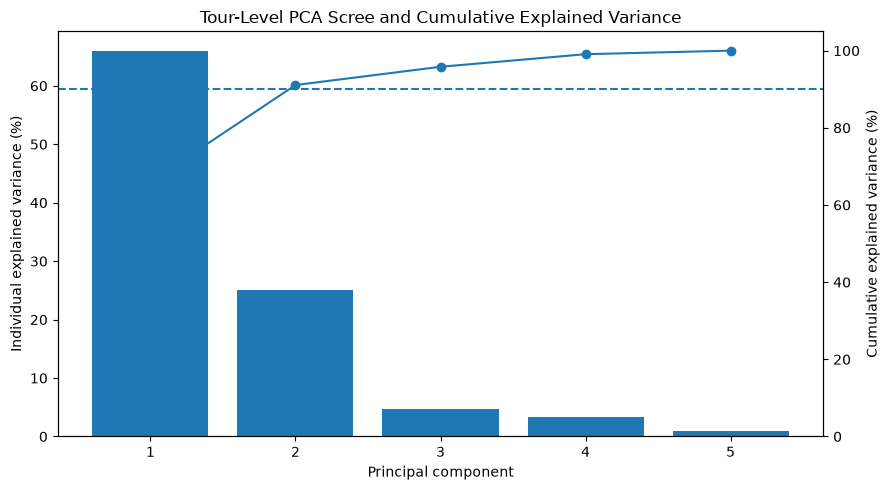

In [11]:
components = np.arange(1, len(pca_full.explained_variance_ratio_) + 1)
individual = pca_full.explained_variance_ratio_ * 100
cumulative = np.cumsum(individual)

fig, ax1 = plt.subplots(figsize=(9, 5))
ax1.bar(components, individual)
ax1.set_xlabel("Principal component")
ax1.set_ylabel("Individual explained variance (%)")
ax1.set_xticks(components)

ax2 = ax1.twinx()
ax2.plot(components, cumulative, marker="o")
ax2.axhline(VARIANCE_THRESHOLD * 100, linestyle="--")
ax2.set_ylabel("Cumulative explained variance (%)")
ax2.set_ylim(0, 105)

plt.title("Tour-Level PCA Scree and Cumulative Explained Variance")
plt.tight_layout()
plt.show()


## 11. Component loadings

The loading signs can flip without changing the PCA solution. Interpret absolute magnitudes and feature contrasts, and name components only after reviewing the actual fitted loadings.


In [12]:
loadings = pd.DataFrame(
    pca_full.components_.T,
    index=X_scaled.columns,
    columns=component_names
)

display(loadings.iloc[:, :n_components_90].round(4))

for pc in loadings.columns[:n_components_90]:
    print(f"\n{pc}: largest absolute loadings")
    display(
        loadings[pc].abs().sort_values(ascending=False)
        .head(min(5, len(loadings)))
        .rename("absolute_loading").to_frame()
    )


,PC1,PC2
total_distance_km,0.4847,0.3788
recorded_track_hours,0.5232,0.0167
elapsed_span_hours,0.4295,-0.4608
distance_based_avg_speed_kmh,0.3685,0.6058
track_count,0.4136,-0.5262



PC1: largest absolute loadings


,absolute_loading
recorded_track_hours,0.523150
total_distance_km,0.484652
elapsed_span_hours,0.429547
track_count,0.413640
distance_based_avg_speed_kmh,0.368536



PC2: largest absolute loadings


,absolute_loading
distance_based_avg_speed_kmh,0.605788
track_count,0.526216
elapsed_span_hours,0.460798
total_distance_km,0.378817
recorded_track_hours,0.016724


## 12. Create reusable outputs

Save the feature definitions, imputer/scaler/PCA parameters, transformed matrices, variance table, loadings, and the eligible tour keys. This supports a reproducible clustering comparison later.

The original input CSV is not overwritten. These files are generated outputs and should be handled according to the repository's `.gitignore` and collaboration plan.


In [13]:
# Preserve key alignment with every saved representation.
keys_out = tour_keys_eligible.copy()

original_out = pd.concat(
    [keys_out, X_imputed.add_prefix("imputed_")], axis=1
)
scaled_out = pd.concat(
    [keys_out, X_scaled.add_prefix("scaled_")], axis=1
)
pca_reduced_out = pd.concat(
    [keys_out, X_pca_reduced.add_prefix("PC")], axis=1
)

original_out.to_csv(OUTPUT_DIR / "tour_level_pca_imputed_features.csv", index=False)
scaled_out.to_csv(OUTPUT_DIR / "tour_level_pca_standardized_features.csv", index=False)
pca_reduced_out.to_csv(OUTPUT_DIR / "tour_level_pca_reduced_scores.csv", index=False)
explained_variance.to_csv(OUTPUT_DIR / "tour_level_pca_explained_variance.csv", index=False)
loadings.to_csv(OUTPUT_DIR / "tour_level_pca_loadings.csv", index=True)

metadata = {
    "analysis_unit": "candidate tour identified by (vehicle_id, tour_id)",
    "input_file": str(DATA_PATH.relative_to(PROJECT_ROOT)),
    "candidate_features": candidate_features,
    "log1p_features": log_features,
    "imputation_strategy": "median",
    "scaling": "StandardScaler",
    "variance_threshold": VARIANCE_THRESHOLD,
    "n_components_retained": n_components_90,
    "cumulative_variance_retained_pct": retained_variance_pct,
    "n_input_tours": int(len(tours)),
    "n_eligible_tours": int(len(X_imputed)),
    "n_features": int(X_imputed.shape[1]),
    "random_state": RANDOM_STATE,
    "notes": [
        "PCA was fitted independently on tour-level data.",
        "Quality flags were not used as PCA features.",
        "Candidate tours are not independently verified real-world trips.",
        "The endpoint-filter exclusion audit reports 17.22% of recorded distance in excluded groups."
    ]
}
with open(OUTPUT_DIR / "tour_level_pca_metadata.json", "w", encoding="utf-8") as f:
    json.dump(metadata, f, indent=2)

print("Saved PCA outputs to:", OUTPUT_DIR)
for path in sorted(OUTPUT_DIR.iterdir()):
    if path.is_file():
        print(f"- {path.name} ({path.stat().st_size:,} bytes)")


Saved PCA outputs to: /Users/divyshah/Downloads/dt-cargo-vehicle-telemetry--main/data/processed/tour_level_pca
- tour_level_pca_explained_variance.csv (359 bytes)
- tour_level_pca_imputed_features.csv (1,364,521 bytes)
- tour_level_pca_loadings.csv (614 bytes)
- tour_level_pca_metadata.json (1,017 bytes)
- tour_level_pca_reduced_scores.csv (630,977 bytes)
- tour_level_pca_standardized_features.csv (1,427,350 bytes)


## 13. Final validation and research notes

Before using these outputs for clustering, confirm:
1. The loaded file and row count match the expected tour-level artifact.
2. `(vehicle_id, tour_id)` keys are unique and aligned across saved matrices.
3. There are no missing values in the imputed, standardized, or PCA matrices.
4. The selected feature list is defensible for the project question.
5. Quality-flagged tours were not blanket-deleted.
6. The report explicitly notes the selection-bias risk: excluded groups account for 17.22% of recorded distance according to the existing audit.
7. Component interpretations are based on the loadings actually produced by this run, not track-level PCA results.

**Next notebook/stage:** compare K-Means on `tour_level_pca_standardized_features.csv` against the reduced PCA scores using the same eligible tours, and assess silhouette, cluster sizes, stability, and operational interpretability.
